# Delta Cards pipeline demo

Set one image path, run the pipeline, and inspect the result.

In [1]:
import asyncio
import glob
import os
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

# Ensure repository root is on sys.path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from delta_cards.recognition.pipeline import CardRecognitionPipeline
from delta_cards.recognition.vector_index import USearchCardIndex


## Select a card image

Use a local image path or an `https://` URL.

In [2]:
IMAGE_SOURCE = ROOT / "data/test_image/00eb499a.webp"
IMAGE_SOURCE = str(IMAGE_SOURCE)
IMAGE_SOURCE


'/home/ubuntu/delta-cards/data/test_image/00eb499a.webp'

## Run the pipeline

In [3]:
# Initialize pipeline with vector index and SQLite metadata
pipeline = CardRecognitionPipeline(
    vector_index=USearchCardIndex(
        index_path=str(ROOT / "data/pokemon_cards.usearch"),
        meta_path=str(ROOT / "data/pokemon_cards_meta.sqlite"),
        view_only=True,
    )
)

# Run recognition (Jupyter natively supports top-level await)
result = await pipeline.process_card_listing(IMAGE_SOURCE)

# Print execution summary
print(f"Status:            {result.get('status')}")
print(f"Extraction Method: {result.get('extraction_method')}")
print(f"Isolation Status:  {result.get('isolation_status')}")
print(f"Confidence:        {result.get('confidence', 0.0):.1%}")

if result.get("verified_card"):
    card = result["verified_card"]
    print("\n--- MATCHED CARD ---")
    print(f"Name:   {card.get('name')}")
    print(f"ID:     {card.get('id')}")
    print(f"Lang:   {card.get('lang')}")
    print(f"Set:    {card.get('set', {}).get('name')} ({card.get('set', {}).get('id')})")
    print(f"Local#: {card.get('localId')}")
    if card.get("rarity"):
        print(f"Rarity: {card.get('rarity')}")
    if card.get("hp"):
        print(f"HP:     {card.get('hp')}")

if result.get("cardmarket"):
    print(f"\nCardmarket: {result['cardmarket'].get('url')}")

print(f"\nElapsed time: {result.get('profiling', {}).get('total_s', 0):.2f}s")


Loading /home/ubuntu/delta-cards/models/riftbound_regions.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.30.0 with CPUExecutionProvider
Status:            success
Extraction Method: fgir_fuzzy_strong_text_confirmed
Isolation Status:  isolated
Confidence:        63.3%

--- MATCHED CARD ---
Name:   Fuecoco
ID:     sv02-034
Lang:   es
Set:    Evoluciones en Paldea (sv02)
Local#: 034
HP:     80

Cardmarket: https://www.cardmarket.com/es/Pokemon/Products?idProduct=715507

Elapsed time: 7.88s


## Display results

### 1. Original image and BBox detection

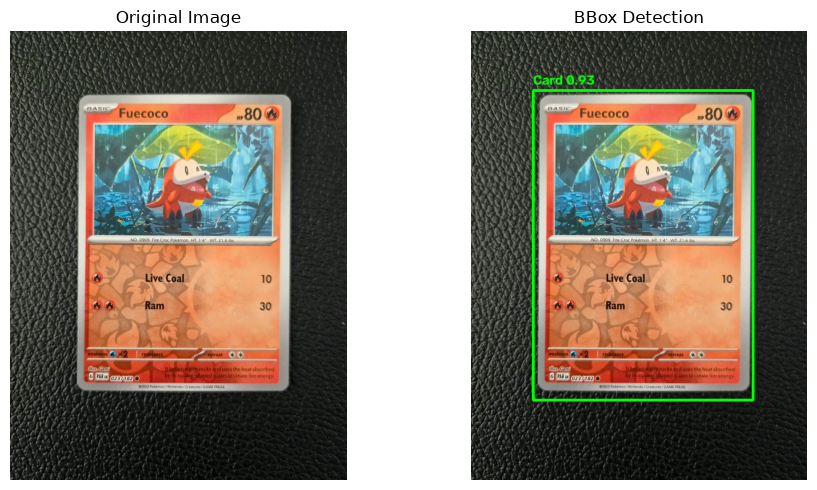

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Original image (handles paths, URLs, and branch compatibility)
if hasattr(pipeline, "isolator") and hasattr(pipeline.isolator, "load_image"):
    orig_img = pipeline.isolator.load_image(IMAGE_SOURCE)
elif hasattr(pipeline, "detector") and hasattr(pipeline.detector, "_load_image"):
    orig_img = pipeline.detector._load_image(IMAGE_SOURCE)
else:
    orig_img = cv2.imread(str(IMAGE_SOURCE))

if orig_img is not None:
    ax1.imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
ax1.set_title("Original Image")
ax1.axis("off")

# BBox Detection / Cropped Card
annotated = result.get("debug_trace", {}).get("annotated_image")
if annotated is not None:
    ax2.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax2.set_title("BBox Detection")
else:
    card_img = result.get("debug_trace", {}).get("card_image")
    if card_img is not None:
        ax2.imshow(cv2.cvtColor(card_img, cv2.COLOR_BGR2RGB))
        ax2.set_title(f"Cropped Card ({result.get('isolation_status', 'fallback')})")
    else:
        ax2.text(0.5, 0.5, "No detection available", ha="center", va="center")
        ax2.set_title("BBox Detection")
ax2.axis("off")

plt.tight_layout()
plt.show()

### 2. Image candidates from USearch (3x5)

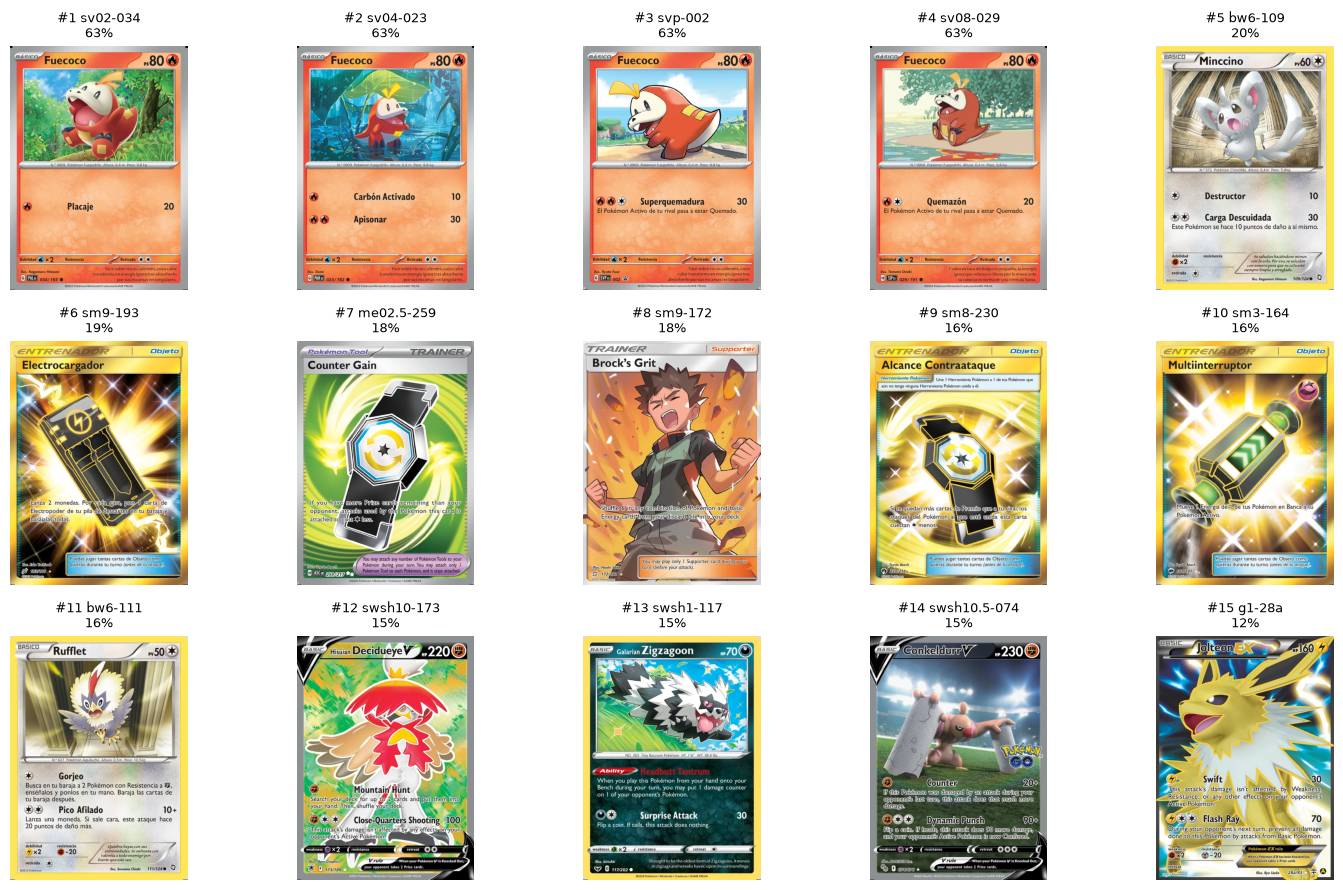

In [5]:
candidates = result.get("debug_trace", {}).get("candidates", [])
detected_lang = result.get("query_ocr", {}).get("detected_language") or result.get("debug_trace", {}).get("winner_language") or "es"
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    if i < len(candidates):
        cand = candidates[i]
        tcgdex_id = cand.get("tcgdex_id") or "unknown"
        score = cand.get("combined_score", cand.get("similarity", 0.0))

        # Try resolving candidate image path via pipeline cache or glob fallback
        img_path = None
        if hasattr(pipeline, "ocr_cache") and hasattr(pipeline.ocr_cache, "resolve_candidate_image_path"):
            img_path = pipeline.ocr_cache.resolve_candidate_image_path(cand, detected_lang) or                        pipeline.ocr_cache.resolve_candidate_image_path(cand, "en")

        if not img_path:
            clean_id = tcgdex_id.replace("-", "_")
            files = glob.glob(f"data/images_cache/*/{clean_id}.webp") or glob.glob(f"data/images_cache/*/{tcgdex_id}.webp")
            if files:
                img_path = files[0]

        img = cv2.imread(img_path) if img_path else None
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.text(0.5, 0.5, "(no cached image)", ha="center", va="center", fontsize=8)

        ax.set_title(f"#{cand.get('rank', i+1)} {tcgdex_id}\n{score:.0%}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3. OCR text from image and candidates with scores

In [6]:
print("--- QUERY OCR TEXT ---")
query_text = result.get("query_ocr", {}).get("full_text", "")
print(query_text if query_text else "(No OCR text detected)")

print("\n--- CANDIDATES OCR TEXT & SCORES ---")
candidates = result.get("debug_trace", {}).get("candidates", [])
for cand in candidates:
    rank = cand.get("rank", "?")
    tcgdex_id = cand.get("tcgdex_id", "unknown")
    score = cand.get("combined_score", cand.get("similarity", 0.0))
    full_text = cand.get("full_text", "")
    if not full_text and hasattr(pipeline.ocr_cache, "get_cached_ocr"):
        cached = pipeline.ocr_cache.get_cached_ocr(tcgdex_id, cand.get("lang", "en"))
        if cached:
            full_text = cached.get("full_text", "")
    elif not full_text and hasattr(pipeline.ocr_cache, "get_cached_text"):
        full_text = pipeline.ocr_cache.get_cached_text(tcgdex_id, cand.get("lang", "en")) or ""

    print(f"[{rank}] {tcgdex_id} (Score: {score:.0%})")
    if full_text:
        print(f"    {full_text.strip()}\n")

--- QUERY OCR TEXT ---
日A5に Fuecoco 80 ドp! NO0JO9 freC0P0LeTCnH+4W215d Live Coal 10 Ram 30 Rheanwatocksnduicsthehcdabsorbed 0237182 レysduhpedsaestocreaetreセnでy

--- CANDIDATES OCR TEXT & SCORES ---
[1] sv02-034 (Score: 63%)
    BASICO Fuecoco 円80 NpO9o9 Pokemon Fuegodrilo Altura.O.4 m Peso.9.8kg Placaje 20 Debilidad ×2 Resistencia Retirada 本本 Yace sobrerocas calientes, cuyocalor Ius. Kogemary Himeno Transforma en energia gneatras absorberlo PALS 034/193 Por susescamasrectangulares. 02O23PokemOnfNintendoCてeatfe5GAMEFREAK

[2] sv04-023 (Score: 63%)
    BASICO Fuecoco 円80 NpO9og PokemonFuegodrilo Altura:O.4 m Peso.9.8 kg Carbón Activado 10 Apisonar 30 Debilidad ×2 Resistcncia Retirada +本 Yacesobrerocas calientes, cuyocalor Ius.Gemi Transformaenenerga fgnea trasabsorberlo PARS 023/182 Por sus escamasrectangulares. 22O23POkemOnfNintendQCeatfeSGAMEFREAK

[3] svp-002 (Score: 63%)
    BASICO Fuecoco 円80 N..O9o9 Pokemon Fuegodrilo Altura:O.4 m Peso: 9,8 kg Superquemadura 30 El Pokemon Activo de

In [ ]:
import easyocr

# 1. Inicializamos el lector indicando el idioma (en este caso inglés 'en')
# La primera vez que ejecutes esto, descargará el modelo de IA automáticamente.
reader = easyocr.Reader(['en'])

# 2. Le pasamos la ruta de la imagen directamente
IMAGE_SOURCE = "/home/ubuntu/delta-cards/data/test_image/00eb499a.webp"
resultados = reader.readtext(IMAGE_SOURCE)

# 3. Mostrar los resultados
# EasyOCR devuelve una lista con las coordenadas, el texto y la confianza de acierto
print("--- Texto Extraído ---")
for caja, texto, confianza in resultados:
    # Filtramos para mostrar solo los textos con una confianza mayor al 20%
    print(f"[{confianza:.2f}] {texto}")

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.
/home/ubuntu/delta-cards/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- Texto Extraído ---
[1.00] Fuecoco
[1.00] 80
[1.00] Live Coal
[1.00] 10
[0.97] Ram
[0.55] 30
[0.49] 023/082


### 4. LLM verification output

In [7]:
from types import SimpleNamespace
from delta_cards.recognition.llm_verifier import get_llm_verifier

candidates = result.get("debug_trace", {}).get("candidates", [])

if candidates:
    top_cand = candidates[0]
    cand_text = top_cand.get("full_text", "")
    if not cand_text and hasattr(pipeline.ocr_cache, "get_cached_ocr"):
        cached = pipeline.ocr_cache.get_cached_ocr(top_cand.get("tcgdex_id"), top_cand.get("lang", "es"))
        if cached:
            cand_text = cached.get("full_text", "")
    elif not cand_text and hasattr(pipeline.ocr_cache, "get_cached_text"):
        cand_text = pipeline.ocr_cache.get_cached_text(top_cand.get("tcgdex_id"), top_cand.get("lang", "es")) or ""

    offer = SimpleNamespace(
        title="",
        description="",
        tcgdex_id=top_cand.get("tcgdex_id", ""),
        language=top_cand.get("lang", "es"),
        _query_ocr=result.get("query_ocr", {}),
        _candidate_ocr={"full_text": cand_text},
    )

    verifier = get_llm_verifier()
    llm_res = verifier.verify_match(
        offer=offer,
        query_ocr=result.get("query_ocr", {}),
        candidate_ocr={"full_text": cand_text},
        tcgdex_card=top_cand.get("card") or top_cand,
    )

    print(f"Candidate:  {top_cand.get('tcgdex_id')}")
    print(f"Verified:   {llm_res.is_verified}")
    print(f"Verdict:    {llm_res.verdict_summary}")
    print(f"Confidence: {llm_res.confidence_score:.0f}%")
    print(f"Inference:  {llm_res.inference_time_s:.2f}s")
    print(f"Raw Output: {llm_res.raw_response}")
else:
    llm_res = None
    print("No candidates available for verification.")

Candidate:  sv02-034
Verified:   False
Verdict:    Veto IA: Veredicto global rechazado
Confidence: 25%
Inference:  97.09s
Raw Output: 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0


In [8]:
llm_res


LLMVerificationResult(is_verified=False, confidence_score=25.0, confirmed_count=18, total_questions=20, checks={'q01_pokemon_name_match': True, 'q02_stage_evolution_match': True, 'q03_hp_alignment': True, 'q04_pokemon_type_consistent': True, 'q05_collector_number_match': False, 'q06_total_card_count_match': True, 'q07_promo_code_alignment': True, 'q08_set_expansion_consistent': True, 'q09_primary_attack_name': True, 'q10_attack_damage_match': True, 'q11_secondary_attack_or_ability': True, 'q12_energy_rules_or_retreat': True, 'q13_ocr_text_subset_valid': True, 'q14_card_mechanic_badge': True, 'q15_rarity_visual_indicator': True, 'q16_no_contradictory_pokemon': True, 'q17_wallapop_title_mentions_card': True, 'q18_wallapop_description_consistent': True, 'q19_single_card_not_bulk_lot': True, 'q20_overall_verdict_genuine_match': False}, questions_detail=[QuestionCheck(id='q01_pokemon_name_match', question='Pokemon name in photo OCR matches TCGdex candidate name', question_es='¿El nombre del

## Test an image outside the database

Set an arbitrary local path or public image URL, then rerun the pipeline and display cells above.

In [9]:
# Example: a local image or any public card-image URL.
# IMAGE_SOURCE = ROOT / "data/evaluation_set/images/sample_015_spanish_xy6-075.jpg"
# IMAGE_SOURCE = "https://images.pokemontcg.io/swsh7/192_hires.png"
#
# Rerun the "Run the pipeline" and display cells above.
